## Aprendizagem Automática (APRAU) - Grupo 01
#### Mestrado em Engenharia Informática
##### First Assignment

- Daniel Braga - 1200801
- Diogo Martins - 1211978
- Gaspar Vieira - 1251542


## Análise Exploratória de Dados (Exploratory Data Analysis, EDA)

In [ ]:
# imports
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

df = pd.read_csv("dataset_grupo_01.csv")
df_comparison = df.copy()  # Copia criada a partir do DataFrame original para comparasões apenas.
TARGET_C, TARGET_R = "target_class", "target_regression" 

In [2]:
# initial analysis of the dataset
print(f"Dimensão inicial: {df.shape}")
print(f"Linhas duplicadas: {df.duplicated().sum()}")
print(f"Valores em falta: {df.isna().sum().sum()}")

display(df.describe().T)

Dimensão inicial: (2000, 35)
Linhas duplicadas: 0
Valores em falta: 0


,count,mean,std,min,25%,50%,75%,max
age,2000.0,49.817500,21.924086,2.000000,31.000000,50.000000,68.000000,89.000000
age_normalized,2000.0,0.549626,0.252001,0.000000,0.333333,0.551724,0.758620,1.000000
bmi,2000.0,27.360674,6.883579,13.750000,22.200000,27.320000,32.402500,68.530000
HbA1c_level,2000.0,5.823790,0.928032,3.500000,5.374129,5.494662,6.750000,9.000000
cholesterol,2000.0,223.647108,34.915456,150.000000,201.000000,224.842938,242.000000,299.000000
sleep_hours,2000.0,6.941153,1.415719,4.000000,6.200000,6.982952,7.700000,10.000000
triglycerides,2000.0,178.811071,66.089529,50.000000,131.750000,179.000000,243.026316,388.000000
blood_pressure,2000.0,149.687674,3.626313,121.000000,148.625000,149.587719,150.654054,176.000000
crp_level,2000.0,7.483729,0.882769,0.467803,7.294863,7.458483,7.767442,14.922016
homocysteine_level,2000.0,12.453406,0.844962,5.309536,12.287763,12.504625,12.681166,19.959139


In [3]:
summary_data = []
for col in df.select_dtypes(include=['object', 'category', 'bool']).columns:
    summary_data.append({
        'Atributo': col,
        'Nº Valores Únicos': df[col].nunique(),
        'Valores Possíveis': list(df[col].unique())
    })

df_summary = pd.DataFrame(summary_data)
display(df_summary)

,Atributo,Nº Valores Únicos,Valores Possíveis
0,age_level,4,"[Mature, Middle, Young, Senior]"
1,gender,2,"[Male, Female]"
2,bmi_level,4,"[Obese, Overweight, Normal, Underweight]"
3,smoking,3,"[Former, Never, Current]"
4,physical_activity,3,"[High, Moderate, Low]"
5,family_history,2,"[No, Yes]"
6,stress_level,3,"[Low, Medium, High]"
7,low_hdl_cholesterol,2,"[No, Yes]"
8,high_ldl_cholesterol,2,"[No, Yes]"
9,sugar_consumption,3,"[Low, Medium, High]"


Aqui identificamos a presensa de 13 atributos com valores não numéricos. Assim, precisamos de transformar os valores verdadeiro/falso em 1/0 e, os restantes, decompor em tableas pelo one-hot encoding em mais atributos. 

In [4]:
# Automatizar a conversão para colunas com exatamente 2 valores únicos (Yes/No)
for col in df.select_dtypes(include=['object', 'category']).columns:
    unique_vals = set(df[col].dropna().unique())
    if unique_vals.issubset({'Yes', 'No'}):
        df[col] = df[col].map({'Yes': 1, 'No': 0})

# Automatizar a conversão para colunas ordinais
ordinal_mappings = {
    'age_level': {'Young': 0, 'Middle': 1, 'Mature': 2, 'Senior': 3},
    'bmi_level': {'Underweight': 0, 'Normal': 1, 'Overweight': 2, 'Obese': 3},
    'stress_level': {'Low': 0, 'Medium': 1, 'High': 2},
    'physical_activity': {'Low': 0, 'Moderate': 1, 'High': 2}
}

for col, mapping in ordinal_mappings.items():
    if col in df.columns:
        df[col] = df[col].map(mapping)
        
# Automatizar a conversão das restantes colunas categóricas para numéricas usando one-hot encoding
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True).astype(int)

In [ ]:
# Validação dos atributos tratados

summary_data = []

for col in df.columns:
    n_unique_curr = df[col].nunique()
    
    if n_unique_curr > 20:
        val_repr_curr = f"Numérica (Min: {df[col].min()}, Max: {df[col].max()})"
    else:
        try:
            val_repr_curr = sorted(list(df[col].unique()))
        except:
            val_repr_curr = list(df[col].unique())
            
    orig_col_candidates = [c for c in df_comparison.columns if col.startswith(c)]
    orig_col = orig_col_candidates[0] if orig_col_candidates else col
    
    n_unique_orig = df_comparison[orig_col].nunique()
    if n_unique_orig > 20:
        val_repr_orig = f"Numérica (Min: {df_comparison[orig_col].min()}, Max: {df_comparison[orig_col].max()})"
    else:
        try:
            val_repr_orig = sorted(list(df_comparison[orig_col].unique()))
        except:
            val_repr_orig = list(df_comparison[orig_col].unique())

    summary_data.append({
        'Atributo': col,
        'Nº Únicos': n_unique_curr,
        'Valores Possíveis / Resumo (Atual)': val_repr_curr,
        'Valores Possíveis / Resumo (Original)': val_repr_orig
    })
df_summary_combined = pd.DataFrame(summary_data)
display(df_summary_combined)

,Atributo,Nº Únicos,Valores Possíveis / Resumo (Atual),Valores Possíveis / Resumo (Original)
0,age_level,4,"[0, 1, 2, 3]","[Mature, Middle, Senior, Young]"
1,bmi_level,4,"[0, 1, 2, 3]","[Normal, Obese, Overweight, Underweight]"
2,age,88,"Numérica (Min: 2, Max: 89)","Numérica (Min: 2, Max: 89)"
3,age_normalized,2,"[0, 1]","Numérica (Min: 2, Max: 89)"
4,bmi,39,"Numérica (Min: 13, Max: 68)","Numérica (Min: 13.75, Max: 68.53)"
5,HbA1c_level,7,"[3, 4, 5, 6, 7, 8, 9]","Numérica (Min: 3.5, Max: 9.0)"
6,cholesterol,150,"Numérica (Min: 150, Max: 299)","Numérica (Min: 150.0, Max: 299.0)"
7,sleep_hours,7,"[4, 5, 6, 7, 8, 9, 10]","Numérica (Min: 4.0, Max: 10.0)"
8,triglycerides,233,"Numérica (Min: 50, Max: 388)","Numérica (Min: 50.0, Max: 388.0)"
9,physical_activity,3,"[0, 1, 2]","[High, Low, Moderate]"


In [6]:
cols_to_drop = set()

const_cols = [
    c
    for c in df.columns
    if df[c].nunique(dropna=False) <= 1
    or df[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.95
]
print("Colunas constantes/quase-constantes a remover:", const_cols)

num_cols = [
    c for c in df.select_dtypes(include="number").columns if c not in const_cols
]

if len(num_cols) > 1:
  corr_matrix = df[num_cols].corr().abs()
  upper = corr_matrix.where(
      np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
  )

  corr_cols = [col for col in upper.columns if any(upper[col] > 0.99)]
  print("Colunas altamente correlacionadas/duplicadas a remover:", corr_cols)
else:
  corr_cols = []

Colunas constantes/quase-constantes a remover: ['age_normalized', 'calcium_baseline', 'plasma_value']
Colunas altamente correlacionadas/duplicadas a remover: ['systolic_index']


Desta primeira análise conseguimos concluir que o calcium_baseline, tal como o nome nome indica, é uma variável constante. Adicionalmente, o systolic_index e systolic_bp apresentam valores indenticos, tal como o ldl e ldl_alternative. Por sua vez, o nome dos atributos age e age_normalize, indicam que, provavelmente, o valor deles será igual.

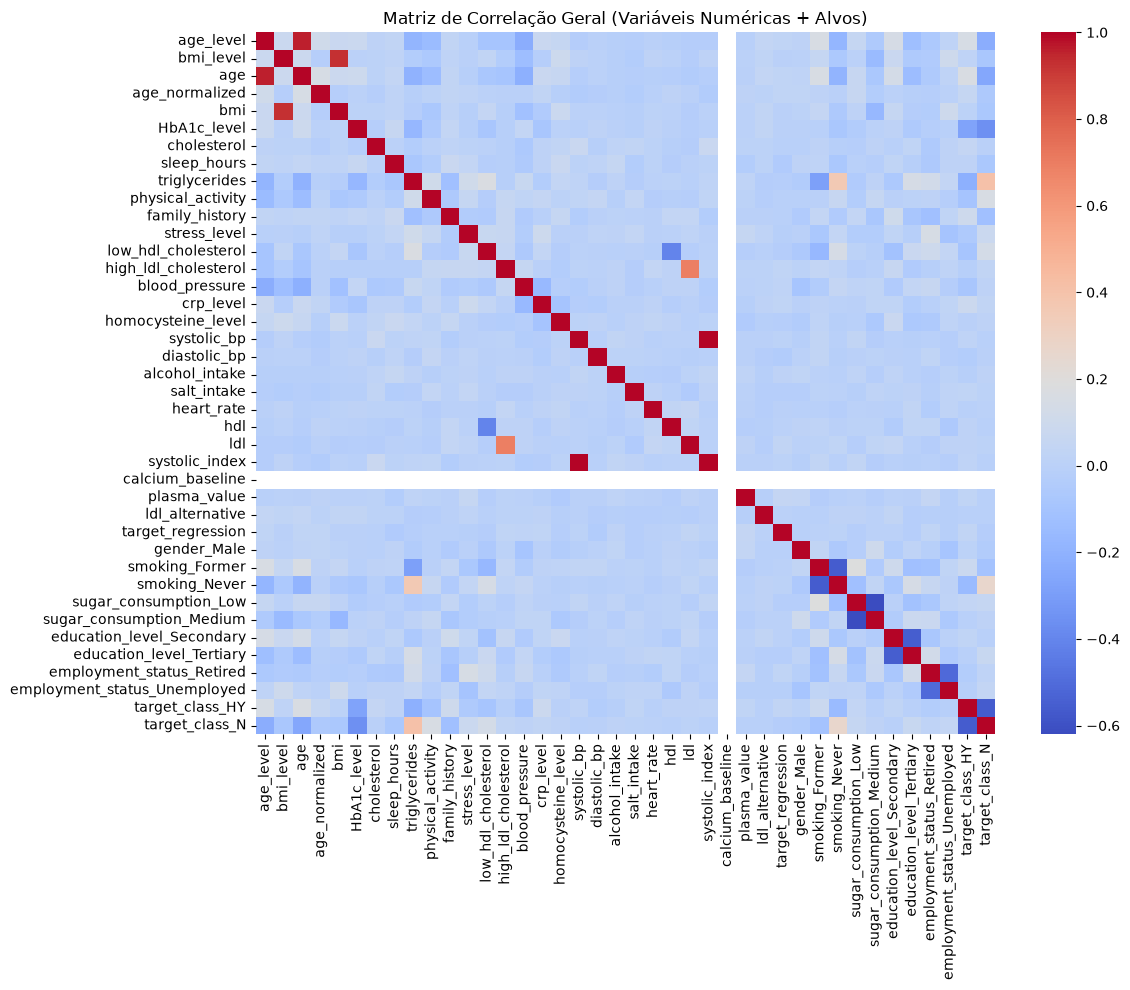

In [ ]:
plt.figure(figsize=(12, 10))
corr_matrix_full = df.corr()

sns.heatmap(corr_matrix_full, cmap="coolwarm")
plt.title("Matriz de Correlação Geral (Variáveis Numéricas + Alvos)")
plt.tight_layout()
plt.show()

Com o recurso a este _heatmap_ conseguimos confirmar que tanto o calcium_baseline, como age e o systolic_index são tabelas que podemos remover para treinar o nosso modelo. Uma vez que ldl e ldl_alternative não têm uma corelação alta, não podemos removelos como pensamos anteriormente. 

Assim, removemos os seguintes atributos:
- **age_normalized**: uma vez que é igual a age;
- **calcium_baseline**: uma vez que é um valor constante, não nos interessa;
- **systolic_index**: uma vez que é igual ao systolic_bp.


Adicionalmente, queremos explorar de forma mais visível a corelação entre os _targets_ e as restantes variáveis.

In [ ]:
columns_to_drop = ['age_normalized', 'calcium_baseline', 'systolic_index']
df = df.drop(columns=columns_to_drop, errors='ignore')

In [ ]:
df_graph = df.copy().drop(['target_class_HY', 'target_class_N', 'target_regression'], axis=1)

if TARGET_R in df_graph.columns:
  print(
      "--- Top correlações com o Alvo de Regressão"
      f" ({TARGET_R}) ---"
  )
  
  corr_target_r = (
      df_graph.select_dtypes(include="number")
      .corr()[TARGET_R]
      .sort_values(ascending=False)
  )

  # Imprimir as 10 mais correlacionadas (positiva e negativamente)
  print(corr_target_r.head(10))
  print("-" * 40)
  print(corr_target_r.tail(10))
  
  print("\n" + "-" * 50)
  print(f"Variáveis com correlação mais próxima de 0")
  print("-" * 50)
  # Calcula o valor absoluto e ordena de forma ascendente
  near_zero_corr = corr_target_r.drop(TARGET_R, errors="ignore").abs().sort_values(ascending=True)
  result_df = pd.DataFrame({
      'Correlação Real': corr_target_r[near_zero_corr.head(10).index],
      'Distância a 0 (|Corr|)': near_zero_corr.head(10)
  })
  print(result_df)

  plt.figure(figsize=(10, 5))
  corr_target_r.drop(TARGET_R, errors="ignore").plot(
      kind="bar", color="cornflowerblue"
  )
  plt.title(f"Correlação das Variáveis com '{TARGET_R}'")
  plt.ylabel("Coeficiente de Correlação")
  plt.xticks(rotation=45, ha="right")
  plt.grid(axis="y", linestyle="--", alpha=0.7)
  plt.tight_layout()
  plt.show()
  
plt.show()

Para o target_regression identificamos que o hdl, bmi, heart rate E ldl_alternative -> por ter um nível de correlação muito perto do 0, a princípio, não serão interessantes para 


--- Top Correlações com a Classe: target_class_HY ---
Top 10 mais positivas:
age                          0.160289
age_level                    0.146185
family_history               0.097431
crp_level                    0.084428
smoking_Former               0.082012
cholesterol                  0.044947
sugar_consumption_Low        0.042844
education_level_Secondary    0.028552
plasma_value                 0.027617
salt_intake                  0.027198
Name: target_class_HY, dtype: float64
----------------------------------------
Top 10 mais negativas:
employment_status_Unemployed   -0.014770
diastolic_bp                   -0.034790
employment_status_Retired      -0.036779
stress_level                   -0.051448
blood_pressure                 -0.087186
low_hdl_cholesterol            -0.092214
physical_activity              -0.095847
smoking_Never                  -0.156197
triglycerides                  -0.212605
HbA1c_level                    -0.276240
Name: target_class_HY, dtype: 

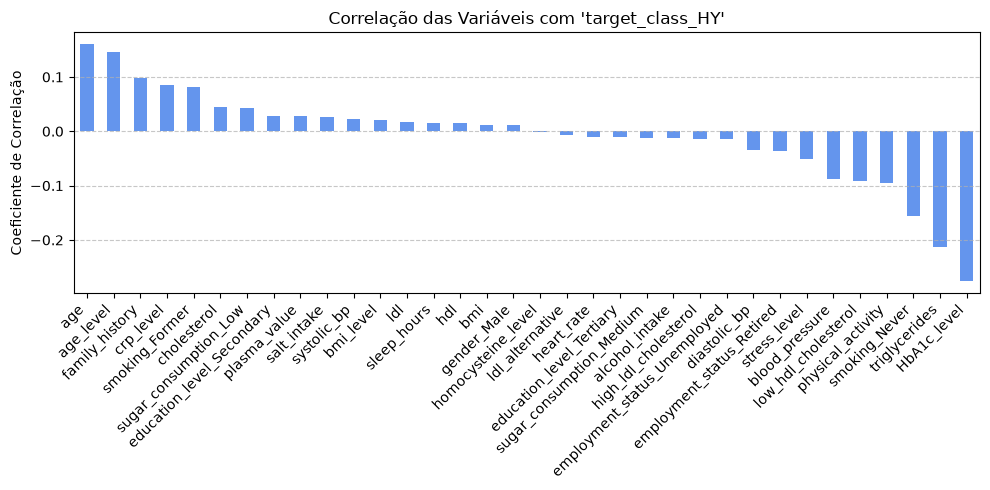


--- Top Correlações com a Classe: target_class_N ---
Top 10 mais positivas:
triglycerides                   0.407075
smoking_Never                   0.264963
physical_activity               0.156796
low_hdl_cholesterol             0.131057
stress_level                    0.077651
education_level_Tertiary        0.064171
sugar_consumption_Low           0.051329
employment_status_Unemployed    0.043650
high_ldl_cholesterol            0.036125
crp_level                       0.035000
Name: target_class_N, dtype: float64
----------------------------------------
Top 10 mais negativas:
hdl              -0.011800
gender_Male      -0.037950
bmi              -0.072001
sleep_hours      -0.075877
bmi_level        -0.075913
smoking_Former   -0.104135
family_history   -0.121279
age_level        -0.226507
age              -0.253801
HbA1c_level      -0.354405
Name: target_class_N, dtype: float64

Top 10 Variáveis com correlação mais próxima de 0:
                           Correlação Real  Distância

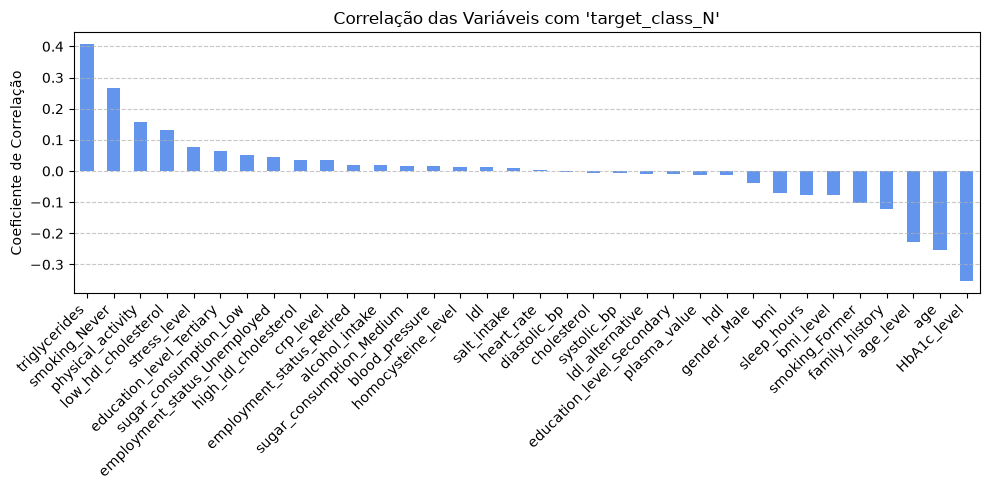


--- Top Correlações com a Classe: target_class_DI_HY ---
Top 10 mais positivas:
HbA1c_level       0.671728
age               0.118152
age_level         0.102270
blood_pressure    0.069891
sleep_hours       0.068057
bmi               0.067149
bmi_level         0.062258
diastolic_bp      0.038850
family_history    0.035344
smoking_Former    0.032017
Name: target_class_DI_HY, dtype: float64
----------------------------------------
Top 10 mais negativas:
stress_level               -0.033709
salt_intake                -0.036660
cholesterol                -0.039590
low_hdl_cholesterol        -0.051441
education_level_Tertiary   -0.059454
physical_activity          -0.076214
sugar_consumption_Low      -0.100161
crp_level                  -0.124248
smoking_Never              -0.134639
triglycerides              -0.234585
Name: target_class_DI_HY, dtype: float64

Top 10 Variáveis com correlação mais próxima de 0:
                           Correlação Real  Distância a 0 (|Corr|)
hdl           

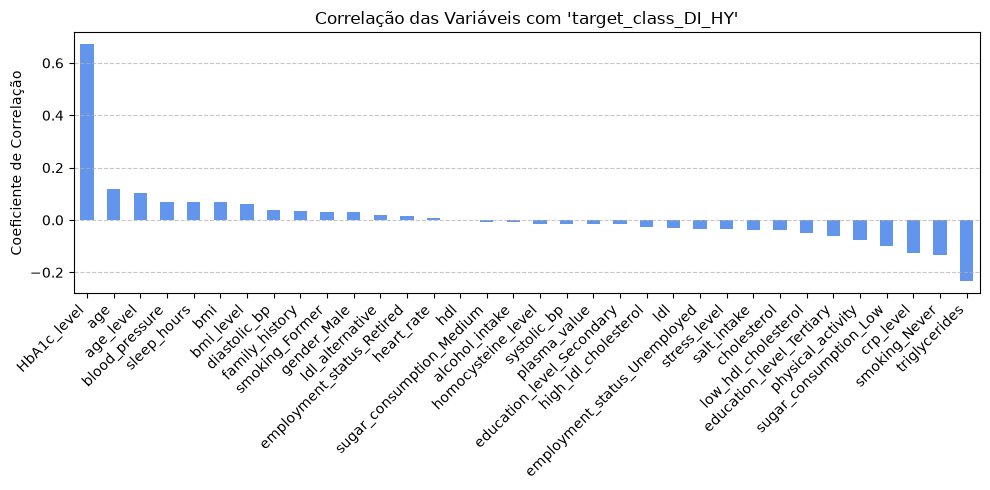

In [ ]:
df['target_class_DI_HY'] = (~df['target_class_HY']) & (~df['target_class_N'])

target_class_cols = ['target_class_HY', 'target_class_N', 'target_class_DI_HY']

corr_data = df_graph.select_dtypes(include="number").copy()
for col in target_class_cols:
    if col in df.columns:
        corr_data[col] = df[col]

corr_matrix = corr_data.corr()

for t_col in target_class_cols:
    if t_col in corr_matrix.columns:
        print(f"\n--- Top Correlações com a Classe: {t_col} ---")
        
        top_corr = corr_matrix[t_col].drop(target_class_cols, errors="ignore").sort_values(ascending=False)
        
        print("Top 10 mais positivas:")
        print(top_corr.head(10))
        print("-" * 40)
        print("Top 10 mais negativas:")
        print(top_corr.tail(10))

        print("\nTop 10 Variáveis com correlação mais próxima de 0:")
        near_zero_corr = top_corr.abs().sort_values(ascending=True)
        
        result_df = pd.DataFrame({
            'Correlação Real': top_corr[near_zero_corr.head(10).index],
            'Distância a 0 (|Corr|)': near_zero_corr.head(10)
        })
        print(result_df)
        print("=" * 42)
        
        plt.figure(figsize=(10, 5))
        top_corr.plot(kind="bar", color="cornflowerblue")
        plt.title(f"Correlação das Variáveis com '{t_col}'")
        plt.ylabel("Coeficiente de Correlação")
        plt.xticks(rotation=45, ha="right")
        plt.grid(axis="y", linestyle="--", alpha=0.7)
        plt.tight_layout()
        plt.show()